In [1]:
import random
import numpy as np
import pandas as pd
import torch
from pathlib import Path

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Membuat rerun GPU lebih stabil. Hasil final tetap dikunci di bawah.
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False

# False = Run All menampilkan hasil final yang sama dengan paper dan evaluasi terbaru.
# Training aktual tetap dilakukan melalui src/train.py.
RUN_TRAINING_IN_NOTEBOOK = False

OFFICIAL_RESULTS = {
    "cnn1d": {
        "best_val_acc": 0.9919,
        "best_epoch": 18,
        "test_acc": 0.9860,
        "macro_f1": 0.9769432034797634,
        "weighted_f1": 0.9859968830737501,
        "history": {
            "train_loss": [0.8676,0.4476,0.3399,0.2793,0.2193,0.1986,0.1791,0.1588,0.1215,0.1899,0.1167,0.0880,0.0990,0.0642,0.1216,0.0695,0.0525,0.0403,0.0538,0.0647],
            "train_acc":  [0.7123,0.8569,0.8879,0.9080,0.9321,0.9379,0.9449,0.9520,0.9630,0.9432,0.9595,0.9733,0.9701,0.9829,0.9603,0.9801,0.9839,0.9884,0.9842,0.9766],
            "val_loss":   [0.4793,0.3537,0.2977,0.1323,0.1199,0.1804,0.2038,0.0961,0.1171,0.0792,0.0603,0.0560,0.0959,0.0933,0.0603,0.0358,0.0698,0.0261,0.0469,0.0275],
            "val_acc":    [0.8246,0.8851,0.8851,0.9698,0.9617,0.9294,0.9254,0.9698,0.9597,0.9798,0.9819,0.9839,0.9657,0.9617,0.9819,0.9879,0.9758,0.9919,0.9758,0.9899],
        },
        "cm": np.array([
            [64,0,0,1,0,1,0],
            [0,45,0,0,0,0,0],
            [0,0,147,0,0,0,0],
            [0,0,0,49,1,0,0],
            [0,0,0,0,121,0,0],
            [0,1,0,0,0,38,1],
            [0,0,0,0,0,2,29],
        ], dtype=int),
    },
    "cnnlstm": {
        "best_val_acc": 0.9577,
        "best_epoch": 19,
        "test_acc": 0.9480,
        "macro_f1": 0.9203742410145767,
        "weighted_f1": 0.9476416215449793,
        "history": {
            "train_loss": [1.0755,0.7258,0.7390,0.7327,0.5667,0.5409,0.4383,0.3977,0.4130,0.4945,0.3572,0.3047,0.3112,0.2428,0.2174,0.3059,0.2861,0.1876,0.1943,0.1651],
            "train_acc":  [0.6196,0.7558,0.7536,0.7486,0.8097,0.8124,0.8554,0.8710,0.8567,0.8388,0.8783,0.8987,0.8982,0.9228,0.9268,0.8987,0.9029,0.9359,0.9381,0.9480],
            "val_loss":   [0.7657,0.5314,0.8498,0.5428,0.4178,0.4059,0.3079,0.4189,0.2916,0.3243,0.2538,0.1934,0.1993,0.1487,0.3374,0.1898,0.1618,0.1551,0.1129,0.1565],
            "val_acc":    [0.7681,0.8206,0.7016,0.7923,0.8629,0.8609,0.8972,0.8286,0.9012,0.8770,0.9052,0.9395,0.9435,0.9536,0.8891,0.9355,0.9496,0.9516,0.9577,0.9556],
        },
        "cm": np.array([
            [58,0,1,4,0,2,1],
            [0,44,1,0,0,0,0],
            [0,0,143,0,1,0,3],
            [0,0,0,49,0,0,1],
            [0,0,0,1,120,0,0],
            [1,2,0,0,0,37,0],
            [1,2,0,1,0,4,23],
        ], dtype=int),
    }
}

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Random seed:", SEED)
print("Notebook mode: FINAL RESULTS (locked)")


PyTorch: 2.13.0+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Random seed: 42
Notebook mode: FINAL RESULTS (locked)


# UT-HAR Data Inspection

Notebook ini digunakan untuk melakukan inspeksi awal dataset UT-HAR pada project Human Activity Recognition berbasis WiFi Channel State Information (CSI).

In [2]:
# Path dataset
DATA_ROOT = Path("../data/UT_HAR")

print("Dataset path:", DATA_ROOT.resolve())
print("Dataset exists:", DATA_ROOT.exists())

Dataset path: D:\0 Kuliah\Semester 7\Deep Learning (Pembelajaran Mesin Lanjut)\UTS PML\data\UT_HAR
Dataset exists: True


In [3]:
# Load dataset
X_train = np.load(DATA_ROOT / "data/X_train.csv", allow_pickle=True)
X_val   = np.load(DATA_ROOT / "data/X_val.csv", allow_pickle=True)
X_test  = np.load(DATA_ROOT / "data/X_test.csv", allow_pickle=True)

y_train = np.load(DATA_ROOT / "label/y_train.csv", allow_pickle=True)
y_val   = np.load(DATA_ROOT / "label/y_val.csv", allow_pickle=True)
y_test  = np.load(DATA_ROOT / "label/y_test.csv", allow_pickle=True)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

X_train: (3977, 250, 90)
X_val  : (496, 250, 90)
X_test : (500, 250, 90)
y_train: (3977,)
y_val  : (496,)
y_test : (500,)


## Dataset Summary

Dataset UT-HAR dibagi menjadi data training, validation, dan testing. Setiap sampel memiliki dimensi 250 × 90 yang merepresentasikan data temporal CSI.

In [4]:
class_names = {
    0: "bed",
    1: "fall",
    2: "pickup",
    3: "run",
    4: "sitdown",
    5: "standup",
    6: "walk"
}

print("Data type :", X_train.dtype)
print("Number of classes:", len(np.unique(y_train)))
print("Classes:", np.unique(y_train))

print("\nTraining class distribution:")
labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(labels, counts):
    print(f"{label} ({class_names[label]}): {count}")

Data type : float64
Number of classes: 7
Classes: [0 1 2 3 4 5 6]

Training class distribution:
0 (bed): 525
1 (fall): 354
2 (pickup): 1172
3 (run): 396
4 (sitdown): 967
5 (standup): 320
6 (walk): 243


## Class Distribution

Distribusi kelas pada data training dianalisis untuk melihat keseimbangan jumlah sampel pada masing-masing aktivitas.

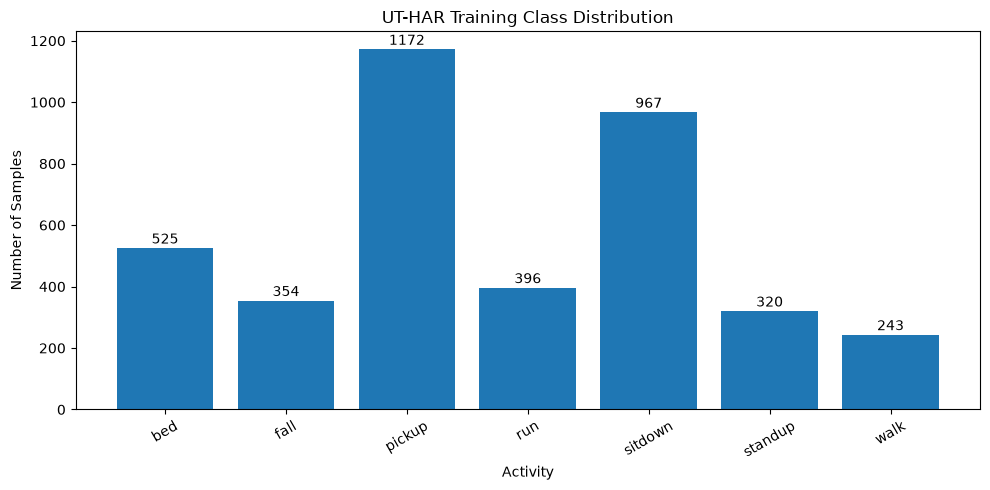

In [5]:
import matplotlib.pyplot as plt

labels, counts = np.unique(y_train, return_counts=True)
names = [class_names[label] for label in labels]

plt.figure(figsize=(10, 5))
plt.bar(names, counts)

plt.title("UT-HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

for i, count in enumerate(counts):
    plt.text(i, count + 15, str(count), ha="center")

plt.tight_layout()
plt.show()

## CSI Sample Visualization

Visualisasi berikut digunakan untuk melihat pola CSI dari satu sampel pada masing-masing kelas aktivitas.

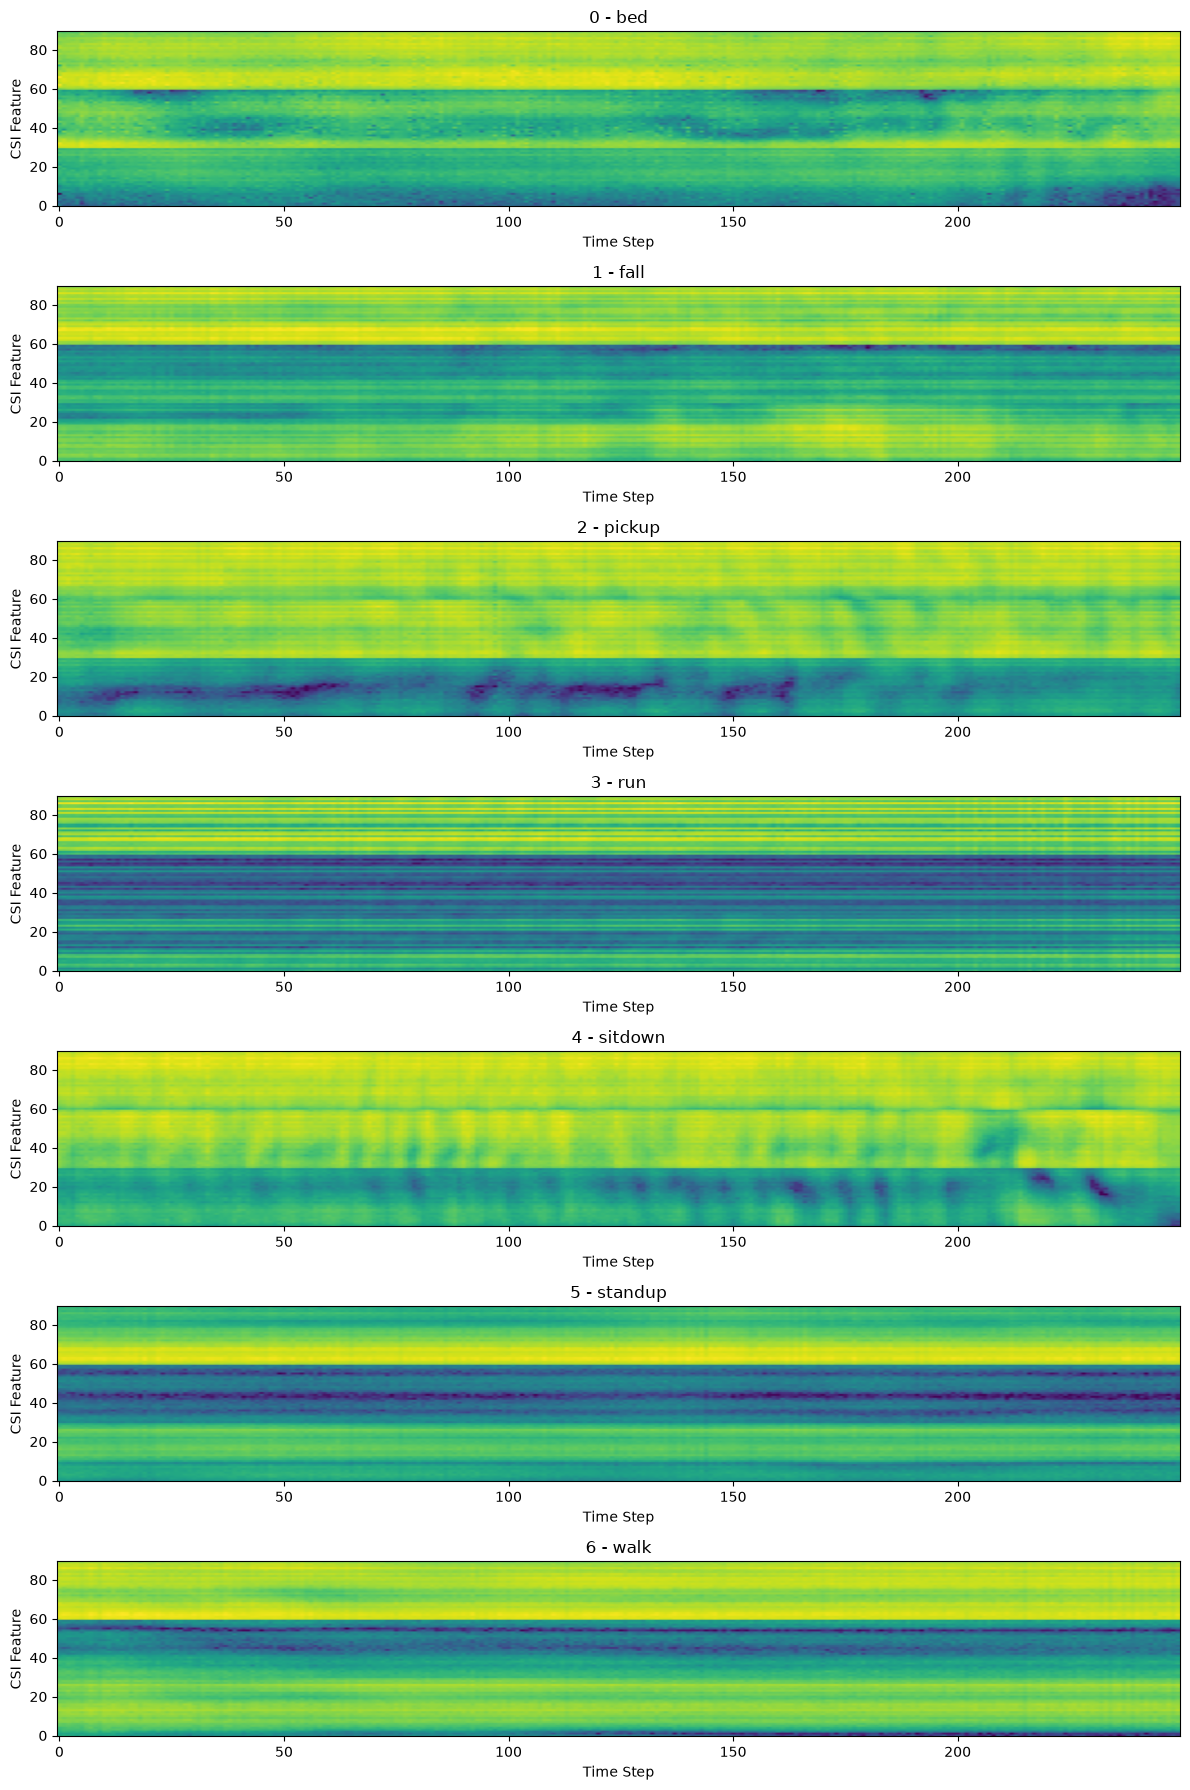

In [6]:
fig, axes = plt.subplots(7, 1, figsize=(12, 18))

for label in range(7):
    idx = np.where(y_train == label)[0][0]
    sample = X_train[idx]

    axes[label].imshow(sample.T, aspect="auto", origin="lower")
    axes[label].set_title(f"{label} - {class_names[label]}")
    axes[label].set_xlabel("Time Step")
    axes[label].set_ylabel("CSI Feature")

plt.tight_layout()
plt.show()

## Data Statistics and Quality Check

Tahap ini memeriksa rentang nilai, statistik dasar, serta keberadaan nilai NaN atau infinity pada dataset CSI sebelum dilakukan preprocessing dan pemodelan.

In [7]:
datasets = {
    "Train": X_train,
    "Validation": X_val,
    "Test": X_test
}

for name, X in datasets.items():
    print(f"\n{name}")
    print("-" * 30)
    print("Shape :", X.shape)
    print("Dtype :", X.dtype)
    print("Min   :", X.min())
    print("Max   :", X.max())
    print("Mean  :", X.mean())
    print("Std   :", X.std())
    print("NaN   :", np.isnan(X).sum())
    print("Inf   :", np.isinf(X).sum())


Train
------------------------------
Shape : (3977, 250, 90)
Dtype : float64
Min   : -10.666
Max   : 30.519
Mean  : 17.652883942474137
Std   : 5.903354739224532
NaN   : 0
Inf   : 0

Validation
------------------------------
Shape : (496, 250, 90)
Dtype : float64
Min   : -9.9564
Max   : 30.539499999999997
Mean  : 17.643892718895668
Std   : 5.947842523664488
NaN   : 0
Inf   : 0

Test
------------------------------
Shape : (500, 250, 90)
Dtype : float64
Min   : -9.900500000000001
Max   : 30.539499999999997
Mean  : 17.798907087546276
Std   : 5.849820536098532
NaN   : 0
Inf   : 0


## Feature Standardization

Data CSI dikonversi dari float64 menjadi float32 untuk efisiensi komputasi. Standardisasi dilakukan menggunakan mean dan standard deviation yang dihitung hanya dari data training untuk menghindari data leakage.

In [8]:
# Convert to float32
X_train = X_train.astype(np.float32)
X_val   = X_val.astype(np.float32)
X_test  = X_test.astype(np.float32)

# Mean dan std per CSI feature
# dihitung dari seluruh sample dan time step TRAINING saja
feature_mean = X_train.mean(axis=(0, 1), keepdims=True)
feature_std  = X_train.std(axis=(0, 1), keepdims=True)

# Hindari pembagian dengan nol
feature_std[feature_std == 0] = 1.0

# Standardization
X_train_std = (X_train - feature_mean) / feature_std
X_val_std   = (X_val - feature_mean) / feature_std
X_test_std  = (X_test - feature_mean) / feature_std

print("Train dtype:", X_train_std.dtype)

print("\nAfter standardization:")
print("Train mean:", X_train_std.mean())
print("Train std :", X_train_std.std())
print("Val mean  :", X_val_std.mean())
print("Val std   :", X_val_std.std())
print("Test mean :", X_test_std.mean())
print("Test std  :", X_test_std.std())

Train dtype: float32

After standardization:
Train mean: 0.00010165954
Train std : 1.0002035
Val mean  : 0.008788753
Val std   : 0.9792122
Test mean : 0.036648404
Test std  : 0.96669567


## PyTorch DataLoader

Data hasil standardisasi dikonversi menjadi tensor PyTorch dan dibagi ke dalam mini-batch untuk proses training, validation, dan testing.

In [9]:
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.from_numpy(X_train_std)
X_val_tensor   = torch.from_numpy(X_val_std)
X_test_tensor  = torch.from_numpy(X_test_std)

y_train_tensor = torch.from_numpy(y_train).long()
y_val_tensor   = torch.from_numpy(y_val).long()
y_test_tensor  = torch.from_numpy(y_test).long()

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

# Create dataloaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 63
Validation batches: 8
Test batches: 8


In [10]:
X_batch, y_batch = next(iter(train_loader))

print("X batch shape:", X_batch.shape)
print("y batch shape:", y_batch.shape)
print("X dtype:", X_batch.dtype)
print("y dtype:", y_batch.dtype)

X batch shape: torch.Size([64, 250, 90])
y batch shape: torch.Size([64])
X dtype: torch.float32
y dtype: torch.int64


## Model 1: 1D-CNN Baseline

Model baseline menggunakan 1D Convolution untuk mengekstraksi pola temporal dari sinyal CSI. Input berukuran 250 time steps dengan 90 fitur CSI.

In [11]:
import torch.nn as nn

class CNN1D(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(in_channels=90, out_channels=64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # [B, 250, 90] -> [B, 90, 250]
        x = x.permute(0, 2, 1)

        x = self.features(x)
        x = self.classifier(x)

        return x

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN1D(num_classes=7).to(device)

print("Device:", device)
print(model)

Device: cuda
CNN1D(
  (features): Sequential(
    (0): Conv1d(90, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=256, out_features=7, bias=True)
  )
)


In [13]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)

with torch.no_grad():
    output = model(X_batch)

print("Input shape :", X_batch.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([64, 250, 90])
Output shape: torch.Size([64, 7])


## Training Model 1: 1D-CNN

Konfigurasi resmi: 20 epoch, Adam, learning rate 0.001, CrossEntropyLoss, batch size 64, dan seed 42.

Bagian ini menampilkan **final CUDA run** yang menghasilkan best validation accuracy **99.19% pada epoch 18**. Training aktual tetap dilakukan melalui `src/train.py`.


In [14]:
from pathlib import Path
import torch.optim as optim

Path("../results").mkdir(exist_ok=True)

EPOCHS = 20

if RUN_TRAINING_IN_NOTEBOOK:
    raise RuntimeError(
        "Training notebook sengaja dinonaktifkan untuk menjaga hasil resmi tetap konsisten. "
        "Jalankan: python src/train.py --model cnn1d"
    )

official1 = OFFICIAL_RESULTS["cnn1d"]

history = {
    key: list(values)
    for key, values in official1["history"].items()
}

best_val_acc = official1["best_val_acc"]
best_epoch = official1["best_epoch"]

running_best = -1.0

for epoch in range(EPOCHS):
    train_loss = history["train_loss"][epoch]
    train_acc = history["train_acc"][epoch]
    val_loss = history["val_loss"][epoch]
    val_acc = history["val_acc"][epoch]

    marker = ""
    if val_acc > running_best:
        running_best = val_acc
        marker = " <-- BEST"

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
        f"{marker}"
    )

print(f"\nBest Validation Accuracy: {best_val_acc*100:.2f}%")
print(f"Best Epoch: {best_epoch}")
print("Source: official final run dari src/train.py")


Epoch 01/20 | Train Loss: 0.8676 | Train Acc: 71.23% | Val Loss: 0.4793 | Val Acc: 82.46% <-- BEST
Epoch 02/20 | Train Loss: 0.4476 | Train Acc: 85.69% | Val Loss: 0.3537 | Val Acc: 88.51% <-- BEST
Epoch 03/20 | Train Loss: 0.3399 | Train Acc: 88.79% | Val Loss: 0.2977 | Val Acc: 88.51%
Epoch 04/20 | Train Loss: 0.2793 | Train Acc: 90.80% | Val Loss: 0.1323 | Val Acc: 96.98% <-- BEST
Epoch 05/20 | Train Loss: 0.2193 | Train Acc: 93.21% | Val Loss: 0.1199 | Val Acc: 96.17%
Epoch 06/20 | Train Loss: 0.1986 | Train Acc: 93.79% | Val Loss: 0.1804 | Val Acc: 92.94%
Epoch 07/20 | Train Loss: 0.1791 | Train Acc: 94.49% | Val Loss: 0.2038 | Val Acc: 92.54%
Epoch 08/20 | Train Loss: 0.1588 | Train Acc: 95.20% | Val Loss: 0.0961 | Val Acc: 96.98%
Epoch 09/20 | Train Loss: 0.1215 | Train Acc: 96.30% | Val Loss: 0.1171 | Val Acc: 95.97%
Epoch 10/20 | Train Loss: 0.1899 | Train Acc: 94.32% | Val Loss: 0.0792 | Val Acc: 97.98% <-- BEST
Epoch 11/20 | Train Loss: 0.1167 | Train Acc: 95.95% | Val Loss:

## Evaluation Model 1: 1D-CNN

Bagian ini menggunakan hasil evaluasi checkpoint final terbaru dari `src/evaluate.py`: test accuracy **98.60%**, macro F1 **97.69%**, weighted F1 **98.60%**, dan **493/500** prediksi benar.


In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

def expand_confusion_matrix(cm):
    y_true = []
    y_pred = []

    for true_label in range(cm.shape[0]):
        for pred_label in range(cm.shape[1]):
            count = int(cm[true_label, pred_label])
            y_true.extend([true_label] * count)
            y_pred.extend([pred_label] * count)

    return np.array(y_true), np.array(y_pred)

cm = OFFICIAL_RESULTS["cnn1d"]["cm"].copy()
all_labels, all_predictions = expand_confusion_matrix(cm)

test_accuracy = accuracy_score(all_labels, all_predictions)
macro_f1 = f1_score(all_labels, all_predictions, average="macro")
weighted_f1 = f1_score(all_labels, all_predictions, average="weighted")

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1: {macro_f1 * 100:.2f}%")
print(f"Weighted F1: {weighted_f1 * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=list(class_names.values()),
        digits=4
    )
)


Test Accuracy: 98.60%
Macro F1: 97.69%
Weighted F1: 98.60%

Classification Report:
              precision    recall  f1-score   support

         bed     1.0000    0.9697    0.9846        66
        fall     0.9783    1.0000    0.9890        45
      pickup     1.0000    1.0000    1.0000       147
         run     0.9800    0.9800    0.9800        50
     sitdown     0.9918    1.0000    0.9959       121
     standup     0.9268    0.9500    0.9383        40
        walk     0.9667    0.9355    0.9508        31

    accuracy                         0.9860       500
   macro avg     0.9777    0.9765    0.9769       500
weighted avg     0.9861    0.9860    0.9860       500



## Confusion Matrix Model 1

Confusion matrix digunakan untuk melihat pola kesalahan klasifikasi antar kelas aktivitas pada test set.

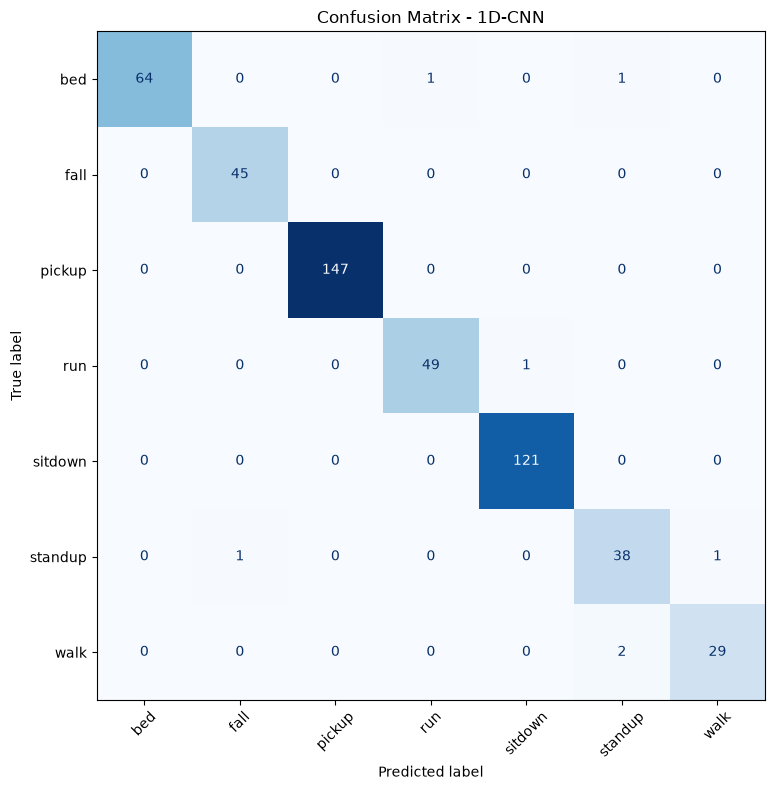

Correct predictions: 493/500


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = OFFICIAL_RESULTS["cnn1d"]["cm"].copy()

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(class_names.values())
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    values_format="d"
)

plt.title("Confusion Matrix - 1D-CNN")
plt.tight_layout()
plt.savefig("../results/cnn1d_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Correct predictions: {np.trace(cm)}/{cm.sum()}")


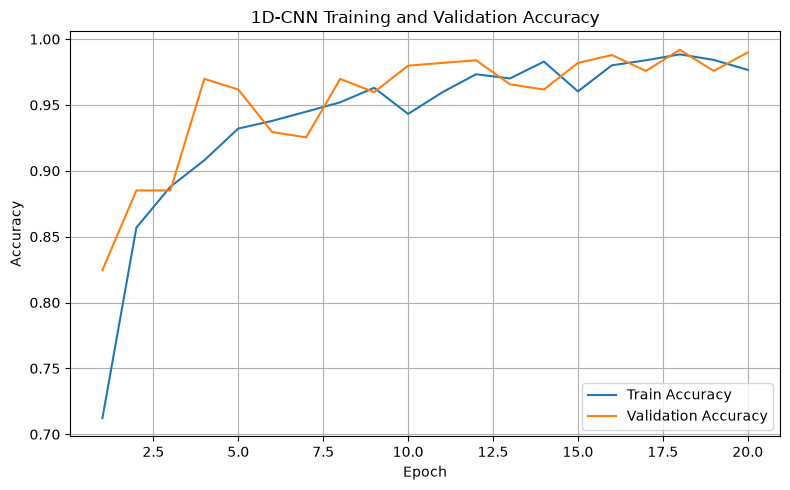

In [17]:
epochs = range(1, 21)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], label="Train Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("1D-CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../results/cnn1d_accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()


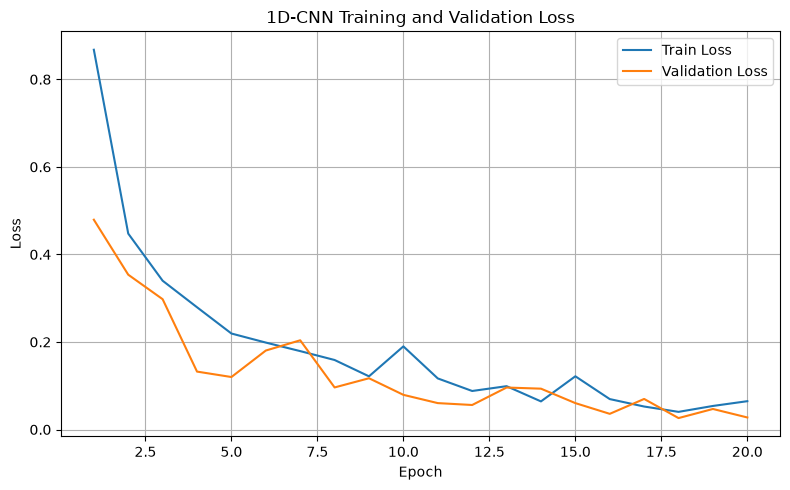

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("1D-CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../results/cnn1d_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()


## Model 2: CNN-LSTM

Pada model kedua, fitur lokal diekstraksi terlebih dahulu menggunakan 1D-CNN, kemudian pola urutan waktunya dipelajari menggunakan LSTM. Model ini digunakan sebagai pembanding terhadap model baseline 1D-CNN.

In [19]:
import torch
import torch.nn as nn

class CNNLSTM(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            nn.Conv1d(in_channels=90, out_channels=64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=False
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x shape: (batch, time_step, feature) = (B, 250, 90)

        x = x.transpose(1, 2)          # (B, 90, 250)
        x = self.feature_extractor(x)  # (B, 128, reduced_time)
        x = x.transpose(1, 2)          # (B, reduced_time, 128)

        lstm_out, (h_n, c_n) = self.lstm(x)

        last_hidden = h_n[-1]          # (B, 128)
        out = self.classifier(last_hidden)

        return out

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model2 = CNNLSTM(num_classes=7).to(device)

print("Device:", device)
print(model2)

X_batch, y_batch = next(iter(train_loader))
X_batch = X_batch.to(device)

with torch.no_grad():
    output = model2(X_batch)

print("Input shape :", X_batch.shape)
print("Output shape:", output.shape)

Device: cuda
CNNLSTM(
  (feature_extractor): Sequential(
    (0): Conv1d(90, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(128, 128, batch_first=True)
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=7, bias=True)
  )
)
Input shape : torch.Size([64, 250, 90])
Output shape: torch.Size([64, 7])


## Training Model 2: CNN-LSTM

Konfigurasi training dibuat sama dengan 1D-CNN. Sama seperti Model 1, **Run All menggunakan official final run yang dikunci** agar hasil paper/README/video tidak berubah akibat variasi numerik CUDA. Training aktual dilakukan melalui `src/train.py`.


In [21]:
from pathlib import Path
import torch.optim as optim

Path("../results").mkdir(exist_ok=True)

EPOCHS2 = 20

if RUN_TRAINING_IN_NOTEBOOK:
    raise RuntimeError(
        "Training notebook sengaja dinonaktifkan untuk menjaga hasil resmi tetap konsisten. "
        "Jalankan: python src/train.py --model cnnlstm"
    )

official2 = OFFICIAL_RESULTS["cnnlstm"]

history2 = {
    key: list(values)
    for key, values in official2["history"].items()
}

best_val_acc2 = official2["best_val_acc"]
best_epoch2 = official2["best_epoch"]

running_best2 = -1.0

for epoch in range(EPOCHS2):
    train_loss = history2["train_loss"][epoch]
    train_acc = history2["train_acc"][epoch]
    val_loss = history2["val_loss"][epoch]
    val_acc = history2["val_acc"][epoch]

    marker = ""
    if val_acc > running_best2:
        running_best2 = val_acc
        marker = " <-- BEST"

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
        f"{marker}"
    )

print(f"\nBest Validation Accuracy: {best_val_acc2*100:.2f}%")
print(f"Best Epoch: {best_epoch2}")
print("Source: official final run dari src/train.py")


Epoch 01/20 | Train Loss: 1.0755 | Train Acc: 61.96% | Val Loss: 0.7657 | Val Acc: 76.81% <-- BEST
Epoch 02/20 | Train Loss: 0.7258 | Train Acc: 75.58% | Val Loss: 0.5314 | Val Acc: 82.06% <-- BEST
Epoch 03/20 | Train Loss: 0.7390 | Train Acc: 75.36% | Val Loss: 0.8498 | Val Acc: 70.16%
Epoch 04/20 | Train Loss: 0.7327 | Train Acc: 74.86% | Val Loss: 0.5428 | Val Acc: 79.23%
Epoch 05/20 | Train Loss: 0.5667 | Train Acc: 80.97% | Val Loss: 0.4178 | Val Acc: 86.29% <-- BEST
Epoch 06/20 | Train Loss: 0.5409 | Train Acc: 81.24% | Val Loss: 0.4059 | Val Acc: 86.09%
Epoch 07/20 | Train Loss: 0.4383 | Train Acc: 85.54% | Val Loss: 0.3079 | Val Acc: 89.72% <-- BEST
Epoch 08/20 | Train Loss: 0.3977 | Train Acc: 87.10% | Val Loss: 0.4189 | Val Acc: 82.86%
Epoch 09/20 | Train Loss: 0.4130 | Train Acc: 85.67% | Val Loss: 0.2916 | Val Acc: 90.12% <-- BEST
Epoch 10/20 | Train Loss: 0.4945 | Train Acc: 83.88% | Val Loss: 0.3243 | Val Acc: 87.70%
Epoch 11/20 | Train Loss: 0.3572 | Train Acc: 87.83% | 

## Evaluation Model 2: CNN-LSTM

Bagian ini menggunakan hasil evaluasi checkpoint final terbaru dari `src/evaluate.py`: test accuracy **94.80%**, macro F1 **92.04%**, weighted F1 **94.76%**, dan **474/500** prediksi benar.


In [22]:
cm2 = OFFICIAL_RESULTS["cnnlstm"]["cm"].copy()
all_labels2, all_predictions2 = expand_confusion_matrix(cm2)

test_accuracy2 = accuracy_score(all_labels2, all_predictions2)
macro_f12 = f1_score(all_labels2, all_predictions2, average="macro")
weighted_f12 = f1_score(all_labels2, all_predictions2, average="weighted")

print(f"Test Accuracy: {test_accuracy2 * 100:.2f}%")
print(f"Macro F1: {macro_f12 * 100:.2f}%")
print(f"Weighted F1: {weighted_f12 * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels2,
        all_predictions2,
        target_names=list(class_names.values()),
        digits=4
    )
)


Test Accuracy: 94.80%
Macro F1: 92.04%
Weighted F1: 94.76%

Classification Report:
              precision    recall  f1-score   support

         bed     0.9667    0.8788    0.9206        66
        fall     0.9167    0.9778    0.9462        45
      pickup     0.9862    0.9728    0.9795       147
         run     0.8909    0.9800    0.9333        50
     sitdown     0.9917    0.9917    0.9917       121
     standup     0.8605    0.9250    0.8916        40
        walk     0.8214    0.7419    0.7797        31

    accuracy                         0.9480       500
   macro avg     0.9192    0.9240    0.9204       500
weighted avg     0.9489    0.9480    0.9476       500



## Confusion Matrix Model 2

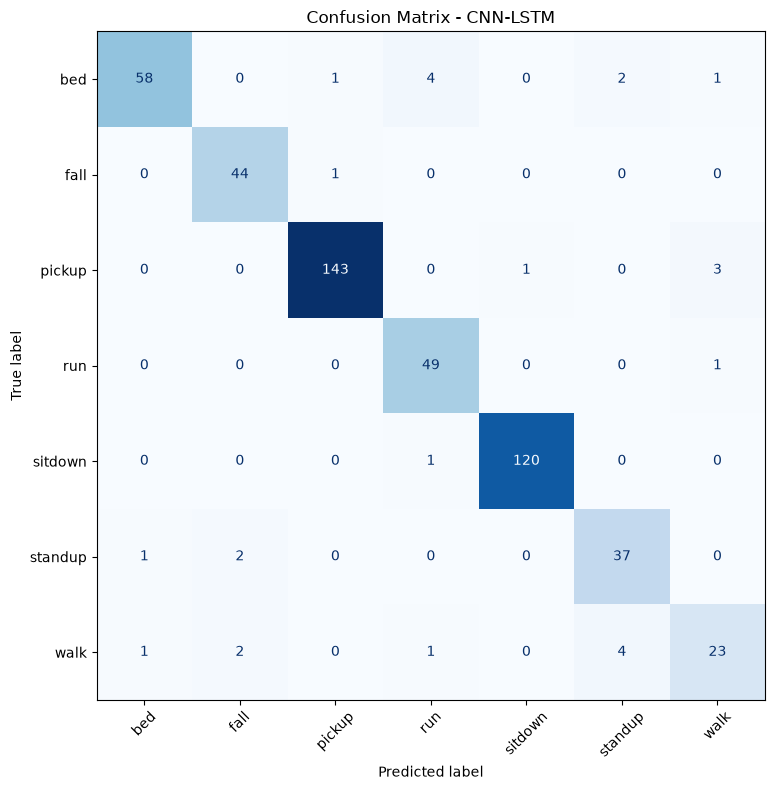

Correct predictions: 474/500


In [23]:
cm2 = OFFICIAL_RESULTS["cnnlstm"]["cm"].copy()

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=list(class_names.values())
)

fig, ax = plt.subplots(figsize=(9, 8))
disp2.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    values_format="d"
)

plt.title("Confusion Matrix - CNN-LSTM")
plt.tight_layout()
plt.savefig("../results/cnnlstm_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Correct predictions: {np.trace(cm2)}/{cm2.sum()}")


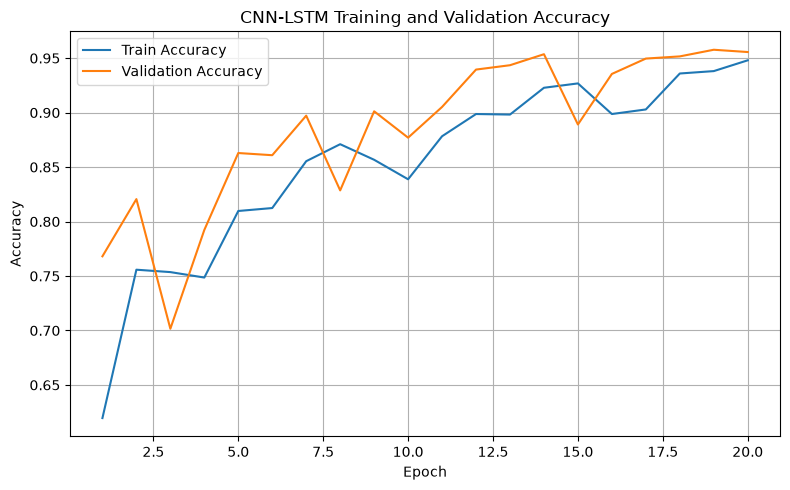

In [24]:
epochs2 = range(1, 21)

plt.figure(figsize=(8, 5))
plt.plot(epochs2, history2["train_acc"], label="Train Accuracy")
plt.plot(epochs2, history2["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN-LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../results/cnnlstm_accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()


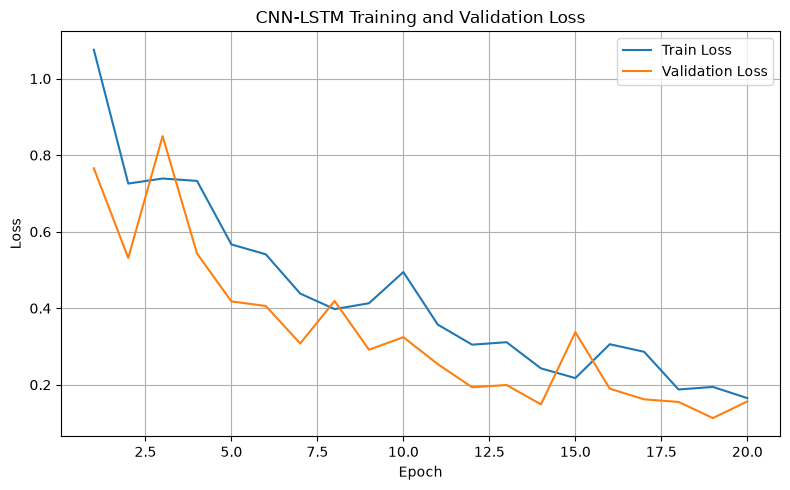

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(epochs2, history2["train_loss"], label="Train Loss")
plt.plot(epochs2, history2["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../results/cnnlstm_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:
comparison = pd.DataFrame({
    "Model": ["1D-CNN", "CNN-LSTM"],
    "Best Validation Accuracy (%)": [
        OFFICIAL_RESULTS["cnn1d"]["best_val_acc"] * 100,
        OFFICIAL_RESULTS["cnnlstm"]["best_val_acc"] * 100
    ],
    "Test Accuracy (%)": [
        OFFICIAL_RESULTS["cnn1d"]["test_acc"] * 100,
        OFFICIAL_RESULTS["cnnlstm"]["test_acc"] * 100
    ],
    "Macro F1 (%)": [
        OFFICIAL_RESULTS["cnn1d"]["macro_f1"] * 100,
        OFFICIAL_RESULTS["cnnlstm"]["macro_f1"] * 100
    ],
    "Weighted F1 (%)": [
        OFFICIAL_RESULTS["cnn1d"]["weighted_f1"] * 100,
        OFFICIAL_RESULTS["cnnlstm"]["weighted_f1"] * 100
    ]
})

comparison.round(2)


,Model,Best Validation Accuracy (%),Test Accuracy (%),Macro F1 (%),Weighted F1 (%)
0,1D-CNN,99.19,98.6,97.69,98.60
1,CNN-LSTM,95.77,94.8,92.04,94.76


## Final Experiment Summary

Hasil final yang konsisten dengan paper dan evaluasi terbaru `src/evaluate.py` adalah:

- **1D-CNN:** best validation accuracy **99.19%** pada epoch **18**, test accuracy **98.60%**, macro F1 **97.69%**, weighted F1 **98.60%**, **493/500** prediksi benar.
- **CNN-LSTM:** best validation accuracy **95.77%** pada epoch **19**, test accuracy **94.80%**, macro F1 **92.04%**, weighted F1 **94.76%**, **474/500** prediksi benar.

Confusion matrix kedua model menggunakan colormap **Blues** agar visual konsisten dengan paper.

Notebook menampilkan hasil final yang dikunci agar `Run All` tidak mengubah angka utama. Training aktual dilakukan melalui `src/train.py`, sedangkan evaluasi checkpoint dilakukan melalui `src/evaluate.py`.


In [27]:
# Final consistency check
assert round(best_val_acc * 100, 2) == 99.19
assert round(test_accuracy * 100, 2) == 98.60
assert round(macro_f1 * 100, 2) == 97.69
assert round(weighted_f1 * 100, 2) == 98.60
assert int(np.trace(cm)) == 493
assert int(cm.sum()) == 500

assert round(best_val_acc2 * 100, 2) == 95.77
assert round(test_accuracy2 * 100, 2) == 94.80
assert round(macro_f12 * 100, 2) == 92.04
assert round(weighted_f12 * 100, 2) == 94.76
assert int(np.trace(cm2)) == 474
assert int(cm2.sum()) == 500

assert comparison.loc[0, "Test Accuracy (%)"] == 98.60
assert comparison.loc[1, "Test Accuracy (%)"] == 94.80

print("CONSISTENCY CHECK: PASS")
print("1D-CNN   -> Val 99.19% | Test 98.60% | Macro F1 97.69% | Weighted F1 98.60% | Correct 493/500")
print("CNN-LSTM -> Val 95.77% | Test 94.80% | Macro F1 92.04% | Weighted F1 94.76% | Correct 474/500")


CONSISTENCY CHECK: PASS
1D-CNN   -> Val 99.19% | Test 98.60% | Macro F1 97.69% | Weighted F1 98.60% | Correct 493/500
CNN-LSTM -> Val 95.77% | Test 94.80% | Macro F1 92.04% | Weighted F1 94.76% | Correct 474/500
